**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053 - Ciencia y analítica de datos**

Tecnológico de Monterrey

Prof Grettel Barceló Alonso

**Semana 4**
Exploración de datos

---

*   NOMBRE: Jacinto Manuel Molina Peralta
*   MATRÍCULA: A01841486

En esta actividad trabajarás con el archivo `personal_loan.csv`, basado en un conjunto de datos sobre clientes bancarios y su comportamiento financiero disponible en Kaggle.

Los datos fueron recopilados para analizar la posibilidad de que los clientes acepten un préstamo personal y contienen información demográfica, financiera y de productos bancarios asociados. Los indicadores incluidos son:

* `ID`: Identificador único del cliente
* `Age`: Edad del cliente (años completos)
* `Experience`: Experiencia laboral en años
* `Income`: Ingreso anual del cliente (en miles de dólares. Por ejemplo, 60 = 60,000 USD/año)
* `ZIP Code`: Código postal del cliente
* `Family`: Número de miembros de la familia
* `CCAvg`: Promedio de gastos mensuales con tarjeta de crédito (en miles de dólares)
* `Education`: Nivel educativo (1 = graduado, 2 = universitario, 3 = posgrado)
* `Mortgage`: Monto de hipoteca que posee el cliente (en miles de dólares)
* `Securities Account`: Indicador de si tiene cuenta de valores (1 = sí, 0 = no)
* `CD Account`: Indicador de si tiene cuenta de certificado de depósito (1 = sí, 0 = no)
* `Online`: Indicador de si usa los servicios bancarios en línea (1 = sí, 0 = no)
* `CreditCard`: Indicador de si es titular de tarjeta de crédito (1 = sí, 0 = no)
* `Personal Loan`: Si el cliente aceptó (1) o no (0) un préstamo personal. Es la variable de salida o *target*, es decir, la que se pretende predecir más adelante al construir el modelo

**NOTA IMPORTANTE:** Asegúrate de responder *explícitamente* todos los cuestionamientos.

In [1]:
# Importar las bibliotecas necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm

1. Descarga el archivo: `personal_loan.csv` y guarda, en un dataframe (`loan_df`), todos sus registros.
* Haz que la columna `ID` sea el índice del dataframe.
* Utiliza el método `info()` del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto?

In [2]:
# 1. Cargar el archivo en un dataframe
loan_df = pd.read_csv('personal_loan.csv')

# 2. Hacer que ID sea el índice
loan_df = loan_df.set_index('ID')

# Guardar el número de registros iniciales (lo usarás en la Parte 1)
n_inicial = len(loan_df)
print('Registros iniciales:', n_inicial)

# 3. Resumen de tipos de datos
loan_df.info()

Registros iniciales: 5037
<class 'pandas.core.frame.DataFrame'>
Index: 5037 entries, 0 to 5036
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Age                 5037 non-null   int64  
 1   Experience          5037 non-null   int64  
 2   Income              5037 non-null   int64  
 3   ZIP Code            5037 non-null   int64  
 4   Family              5037 non-null   int64  
 5   CCAvg               5037 non-null   float64
 6   Education           5037 non-null   float64
 7   Mortgage            5037 non-null   int64  
 8   Personal Loan       5037 non-null   object 
 9   Securities Account  5037 non-null   object 
 10  CD Account          5037 non-null   object 
 11  Online              5037 non-null   object 
 12  CreditCard          5037 non-null   object 
dtypes: float64(2), int64(6), object(5)
memory usage: 550.9+ KB


Al usar info() se ve que el dataframe tiene 5037 registros y 13 columnas. De esas, 8 son numéricas (6 son int64 y 2 son float64) y 5 son de texto (object).

Algo que me llamó la atención es que las 5 columnas de texto son las que deberían ser binarias (Personal Loan, Securities Account, CD Account, Online y CreditCard). Si solo deberían tener 0 y 1, pandas tendría que haberlas leído como números, así que seguramente tienen valores escritos de otra forma, como “Yes” o “No”. Esto lo voy a revisar en la limpieza.

También noté que Education aparece como float64, aunque solo debería tener los valores 1, 2 y 3, así que puede haber algún valor raro. Y ZIP Code aparece como número, pero en realidad es un código postal, entonces no tiene sentido hacer cálculos con él.

# Limpieza

2. Obtén las estadísticas descriptivas de las variables numéricas y examina cuidadosamente los valores obtenidos de cada columna.
* Filtra el dataframe para visualizar los registros en que la edad supera los 100 años y elimínalos si no son pausibles.
* Analiza el resto de las variables y elimina aquellos registros que contengan valores inválidos o inconsistentes. Para cada acción que realices, justifica la decisión, explicando por qué consideras que el valor es incorrecto.
* ¿Cuántos registros se eliminaron (considerando todas las acciones de este ejercicio) y qué porcentaje representa respecto al total del dataframe inicial?

In [3]:
loan_df.describe()

,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage
count,5037.000000,5037.000000,5037.000000,5037.000000,5037.000000,5037.000000,5037.000000,5037.000000
mean,45.411356,20.122494,73.898352,93152.865595,2.394679,1.942404,1.880941,56.500695
std,11.646805,11.461278,46.130504,2119.637960,1.151145,1.755954,0.843337,101.657580
min,23.000000,-3.000000,8.000000,9307.000000,-3.000000,0.000000,1.000000,0.000000
25%,35.000000,10.000000,39.000000,91911.000000,1.000000,0.700000,1.000000,0.000000
50%,45.000000,20.000000,64.000000,93437.000000,2.000000,1.500000,2.000000,0.000000
75%,55.000000,30.000000,98.000000,94608.000000,3.000000,2.600000,3.000000,101.000000
max,144.000000,43.000000,224.000000,96651.000000,4.000000,10.000000,7.300000,635.000000


Revisando los valores mínimos y máximos, encontré varios datos que no tienen sentido:

En Age hay un máximo de 144 años, lo cual no es posible.
En Experience el mínimo es -3, pero la experiencia no puede ser negativa.
En Family también hay un -3, y una familia debería tener al menos 1 miembro.
En Education el máximo es 7.3, cuando solo debería haber valores 1, 2 o 3.
En ZIP Code el mínimo es 9307, que tiene solo 4 dígitos, y los códigos postales de EE. UU. tienen 5.

Income, CCAvg y Mortgage tienen rangos que sí parecen razonables. En Mortgage la mayoría tiene 0, pero eso solo significa que no tienen hipoteca.

In [4]:
loan_df[loan_df['Age'] > 100]

,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,
10,123,39,105,94710,4,2.4,3.0,0,0,0,0,No,0
250,144,6,29,94305,3,1.0,2.0,117,0,No,0,No,No
4800,130,7,73,94028,1,2.5,1.0,135,0,No,0,0,0


In [5]:
loan_df = loan_df[loan_df['Age'] <= 100]
print('Registros después de eliminar edades mayores a 100:', len(loan_df))

Registros después de eliminar edades mayores a 100: 5034


Encontré 3 registros con edades mayores a 100 años (123, 144 y 130). Decidí eliminarlos porque no son edades realistas para clientes de un banco. Además, no cuadran con la experiencia: por ejemplo, el cliente con 144 años tiene solo 6 años de experiencia, lo que significaría que empezó a trabajar a los 138 años. Lo más probable es que sean errores al capturar los datos.

In [6]:
print('Registros con experiencia negativa:', (loan_df['Experience'] < 0).sum())
loan_df[loan_df['Experience'] < 0]

Registros con experiencia negativa: 53


,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,
89,25,-1,113,94303,4,2.30,3.0,0,No,No,0,No,Yes
226,24,-1,39,94085,2,1.70,2.0,0,0,No,0,No,0
315,24,-2,51,90630,3,0.30,3.0,0,0,No,No,1,0
451,28,-2,48,94132,2,1.75,3.0,89,0,No,0,1,No
524,24,-1,75,93014,4,0.20,1.0,0,0,No,No,Yes,0
536,25,-1,43,92173,3,2.40,2.0,176,No,No,0,1,0
540,25,-1,109,94010,4,2.30,3.0,314,0,No,No,1,0
576,25,-1,48,92870,3,0.30,3.0,0,0,No,0,0,1
583,24,-1,38,95045,2,1.70,2.0,0,No,No,No,Yes,0


In [7]:
loan_df = loan_df[loan_df['Experience'] >= 0]
print('Registros después de eliminar experiencia negativa:', len(loan_df))

Registros después de eliminar experiencia negativa: 4981


Encontré 53 registros con experiencia laboral negativa (valores de -1, -2 y -3). Los eliminé porque no es posible tener años de experiencia negativos, el mínimo debería ser 0. Algo que noté es que todos estos clientes son jóvenes (entre 23 y 29 años), así que seguramente son personas con poca o ninguna experiencia y el dato se capturó mal. Otra opción hubiera sido cambiarlos a 0, pero como no sabemos cuál era el valor real, preferí eliminarlos.

In [8]:
print('Registros con Family menor a 1:', (loan_df['Family'] < 1).sum())
loan_df[loan_df['Family'] < 1]

Registros con Family menor a 1: 2


,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,
15,60,30,22,95054,-1,1.5,3.0,0,0,No,0,Yes,Yes
3000,40,14,164,94720,-3,4.3,2.0,0,1,No,No,No,No


In [9]:
loan_df = loan_df[loan_df['Family'] >= 1]
print('Registros después de eliminar Family inválido:', len(loan_df))

Registros después de eliminar Family inválido: 4979


Encontré 2 registros con valores negativos en Family (-1 y -3). Los eliminé porque Family es el número de miembros de la familia, y no puede ser negativo. Como mínimo debería ser 1, que sería el propio cliente.

In [10]:
print('Registros con Education inválido:', (~loan_df['Education'].isin([1, 2, 3])).sum())
loan_df[~loan_df['Education'].isin([1, 2, 3])]

Registros con Education inválido: 1


,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,
347,25,0,43,94305,2,1.6,7.3,0,0,Yes,Yes,1,Yes


In [11]:
loan_df = loan_df[loan_df['Education'].isin([1, 2, 3])]
print('Registros después de eliminar Education inválido:', len(loan_df))

Registros después de eliminar Education inválido: 4978


Encontré 1 registro con Education = 7.3. Lo eliminé porque esta variable solo puede tomar los valores 1 (graduado), 2 (universitario) o 3 (posgrado). Un 7.3 no corresponde a ningún nivel educativo, y además tiene decimales, cuando debería ser un número entero.

In [12]:
zip_texto = loan_df['ZIP Code'].astype(str)
print('Registros con ZIP Code inválido:', (zip_texto.str.len() != 5).sum())
loan_df[zip_texto.str.len() != 5]

Registros con ZIP Code inválido: 1


,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,
384,51,25,21,9307,4,0.6,3.0,0,No,0,0,1,Yes


In [13]:
loan_df = loan_df[loan_df['ZIP Code'].astype(str).str.len() == 5]
print('Registros después de eliminar ZIP Code inválido:', len(loan_df))

Registros después de eliminar ZIP Code inválido: 4977


Encontré 1 registro con ZIP Code = 9307, que solo tiene 4 dígitos. Lo eliminé porque los códigos postales de Estados Unidos siempre tienen 5 dígitos, así que este no es un código válido. Puede que le falte un número, pero como no sabemos cuál es, no se puede corregir.

In [14]:
loan_df.describe()

,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage
count,4977.000000,4977.000000,4977.000000,4977.000000,4977.000000,4977.000000,4977.000000,4977.000000
mean,45.582479,20.356038,73.957002,93167.200121,2.390999,1.940719,1.877034,56.675708
std,11.306960,11.299428,46.207027,1762.076415,1.148632,1.756818,0.839722,101.824409
min,24.000000,0.000000,8.000000,90005.000000,1.000000,0.000000,1.000000,0.000000
25%,36.000000,11.000000,39.000000,91911.000000,1.000000,0.700000,1.000000,0.000000
50%,46.000000,20.000000,64.000000,93437.000000,2.000000,1.500000,2.000000,0.000000
75%,55.000000,30.000000,98.000000,94608.000000,3.000000,2.600000,3.000000,101.000000
max,67.000000,43.000000,224.000000,96651.000000,4.000000,10.000000,3.000000,635.000000


In [15]:
eliminados = n_inicial - len(loan_df)
porcentaje = eliminados / n_inicial * 100
print('Registros eliminados:', eliminados)
print('Porcentaje respecto al total inicial:', round(porcentaje, 2), '%')

Registros eliminados: 60
Porcentaje respecto al total inicial: 1.19 %


En total eliminé 60 registros: 3 por edades mayores a 100, 53 por experiencia negativa, 2 por Family negativo, 1 por Education inválido y 1 por ZIP Code inválido. Esto representa el 1.19 % del total inicial de 5037 registros. Es un porcentaje muy bajo, así que no se pierde mucha información y los datos que quedan son más confiables. Con el nuevo describe() se ve que ya todos los valores están en rangos lógicos.

3. Obtén las estadísticas descriptivas de las variables de texto e imprime las frecuencias de sus categorías.
* Algunas columnas almacenan valores binarios utilizando distintos formatos. Unifica estos valores de manera consistente, asegurándote de que coincidan con la descripción de las variables al inicio de esta libreta.

In [16]:
loan_df.describe(include='object')

,Personal Loan,Securities Account,CD Account,Online,CreditCard
count,4977,4977,4977,4977,4977
unique,4,4,4,4,4
top,0,No,No,Yes,0
freq,3475,2693,2462,1700,2628


In [17]:
for columna in loan_df.select_dtypes(include='object').columns:
    print('---', columna, '---')
    print(loan_df[columna].value_counts())
    print()

--- Personal Loan ---
Personal Loan
0      3475
No     1017
Yes     368
1       117
Name: count, dtype: int64

--- Securities Account ---
Securities Account
No     2693
0      1765
Yes     390
1       129
Name: count, dtype: int64

--- CD Account ---
CD Account
No     2462
0      2212
1       163
Yes     140
Name: count, dtype: int64

--- Online ---
Online
Yes    1700
No     1628
1      1275
0       374
Name: count, dtype: int64

--- CreditCard ---
CreditCard
0      2628
Yes     907
No      885
1       557
Name: count, dtype: int64



In [18]:
binarias = ['Personal Loan', 'Securities Account', 'CD Account', 'Online', 'CreditCard']

for columna in binarias:
    loan_df[columna] = loan_df[columna].replace({'Yes': '1', 'No': '0'}).astype(int)
    print('---', columna, '---')
    print(loan_df[columna].value_counts())
    print()

--- Personal Loan ---
Personal Loan
0    4492
1     485
Name: count, dtype: int64

--- Securities Account ---
Securities Account
0    4458
1     519
Name: count, dtype: int64

--- CD Account ---
CD Account
0    4674
1     303
Name: count, dtype: int64

--- Online ---
Online
1    2975
0    2002
Name: count, dtype: int64

--- CreditCard ---
CreditCard
0    3513
1    1464
Name: count, dtype: int64



Al revisar las frecuencias, vi que las 5 columnas binarias (Personal Loan, Securities Account, CD Account, Online y CreditCard) tenían 4 valores distintos: 0, 1, Yes y No. Según la descripción de las variables, solo deberían tener 1 (sí) y 0 (no). Para unificarlas, cambié “Yes” por 1 y “No” por 0, y convertí las columnas a número entero. Después de esto, cada columna quedó con solo dos valores. Por ejemplo, en Personal Loan quedaron 4492 clientes que no aceptaron el préstamo y 485 que sí.

4. Verifica si hay registros duplicados y si fuera así, elimínalos del dataframe.
* Asegúrate de reiniciar el índice para mantener una secuencia continua tras todas las eliminaciones de registros que hasta este punto se han realizado.

In [19]:
print('Registros duplicados:', loan_df.duplicated().sum())
loan_df[loan_df.duplicated(keep=False)].sort_values(by=['Age', 'Income'])

Registros duplicados: 36


,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,
1160,28,1,40,95134,1,2.0,2.0,0,0,1,0,1,0
5031,28,1,40,95134,1,2.0,2.0,0,0,1,0,1,0
3673,34,9,65,95134,4,1.3,1.0,0,0,0,0,0,1
5032,34,9,65,95134,4,1.3,1.0,0,0,0,0,0,1
1202,35,11,24,95521,4,0.4,2.0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
5016,64,39,38,92024,1,1.1,3.0,108,0,0,0,0,0
737,64,37,138,94709,2,2.8,2.0,0,1,0,0,1,0
5026,64,37,138,94709,2,2.8,2.0,0,1,0,0,1,0


In [20]:
loan_df = loan_df.drop_duplicates()
print('Registros después de eliminar duplicados:', len(loan_df))
print('Duplicados restantes:', loan_df.duplicated().sum())

Registros después de eliminar duplicados: 4941
Duplicados restantes: 0


In [21]:
loan_df = loan_df.reset_index(drop=True)
loan_df.head()

,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
0,25,1,49,91108,4,1.6,1.0,0,0,1,0,0,0
1,45,19,34,90089,3,1.5,1.0,0,0,1,0,0,0
2,39,15,11,94720,1,1.0,1.0,0,0,0,0,0,0
3,35,9,100,94112,1,2.7,2.0,0,0,0,0,0,0
4,35,8,45,91330,4,1.0,2.0,0,0,0,0,0,1


Encontré 36 registros duplicados, es decir, filas que tenían exactamente los mismos valores en todas las columnas que otro registro. Noté que en cada par, una de las copias tenía un ID mayor a 5000, así que parece que se agregaron de más al dataset. Los eliminé con drop_duplicates(), que se queda con la primera aparición, y quedaron 4941 registros.

Después reinicié el índice para que las filas quedaran numeradas de forma continua, ya que con todas las eliminaciones habían quedado huecos. Usé drop=True para no conservar la columna ID, porque es solo un identificador y no aporta información para el análisis.

5. Aunque hasta ahora se han considerado los tipos de datos inferidos por pandas, antes del EDA es recomendable revisar la naturaleza estadística de cada variable (continua, discreta, categórica, binaria, etc.) para aplicar el análisis adecuado.

* Efectúa las siguientes conversiones:
  - Nominal: ZIP Code - `object`
  - Ordinal: Education - `category` con orden 1, 2, 3
  - Binarias: Personal Loan, Securities Account, CD Account, Online, CreditCard - `category`
* Crea dos listas llamadas `num_cols` y `cat_cols` que contengan los nombres de las variables numéricas (int64, float64) y categóricas (object, category) del dataset, respectivamente.

In [22]:
# Nominal: ZIP Code como texto
loan_df['ZIP Code'] = loan_df['ZIP Code'].astype(str)

# Ordinal: Education como categoría con orden 1 < 2 < 3
loan_df['Education'] = pd.Categorical(loan_df['Education'].astype(int),
                                      categories=[1, 2, 3], ordered=True)

# Binarias: como categoría
for columna in binarias:
    loan_df[columna] = loan_df[columna].astype('category')

loan_df.dtypes

,0
Age,int64
Experience,int64
Income,int64
ZIP Code,object
Family,int64
CCAvg,float64
Education,category
Mortgage,int64
Personal Loan,category
Securities Account,category


In [23]:
num_cols = loan_df.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = loan_df.select_dtypes(include=['object', 'category']).columns.tolist()

print('Numéricas:', num_cols)
print('Categóricas:', cat_cols)

Numéricas: ['Age', 'Experience', 'Income', 'Family', 'CCAvg', 'Mortgage']
Categóricas: ['ZIP Code', 'Education', 'Personal Loan', 'Securities Account', 'CD Account', 'Online', 'CreditCard']


Cambié los tipos de datos según lo que realmente representa cada variable. ZIP Code lo convertí a texto porque es un código postal: aunque tiene números, no tiene sentido sacarle promedio o sumarlo. Education la convertí a categoría ordenada, porque sus valores son niveles (graduado, universitario y posgrado) que sí tienen un orden. Las variables binarias las pasé a categoría porque sus 0 y 1 significan “no” y “sí”, no son cantidades.

Al final quedaron 6 variables numéricas (Age, Experience, Income, Family, CCAvg y Mortgage) y 7 categóricas (ZIP Code, Education, Personal Loan, Securities Account, CD Account, Online y CreditCard).

# Análisis exploratorio de datos (univariado)

6. Para el análisis de las variables numéricas obtén nuevamente las estadísticas descriptivas incluyendo los valores de simetría y curtosis.
* Clasifica las variables `Age`, `Income` y `Mortgage` según los valores observados de asimetría y curtosis.

In [24]:
descriptivos = loan_df[num_cols].describe().T
descriptivos['asimetria'] = loan_df[num_cols].skew()
descriptivos['curtosis'] = loan_df[num_cols].kurt()
descriptivos

,count,mean,std,min,25%,50%,75%,max,asimetria,curtosis
Age,4941.0,45.560210,11.315617,24.0,36.0,46.0,55.0,67.0,-0.022754,-1.161599
Experience,4941.0,20.335357,11.308351,0.0,11.0,20.0,30.0,43.0,-0.015216,-1.134857
Income,4941.0,73.826553,46.106768,8.0,39.0,64.0,98.0,224.0,0.841991,-0.046164
Family,4941.0,2.391621,1.148244,1.0,1.0,2.0,3.0,4.0,0.159463,-1.403842
CCAvg,4941.0,1.935855,1.748406,0.0,0.7,1.5,2.6,10.0,1.594670,2.635545
Mortgage,4941.0,56.663631,101.875349,0.0,0.0,0.0,101.0,635.0,2.103865,4.760021


Age: tiene una asimetría de -0.02, que es prácticamente 0, así que es una distribución simétrica. Su curtosis es -1.16, por lo que es platicúrtica, o sea más aplanada que una normal. Esto quiere decir que las edades están repartidas de forma bastante pareja entre los 24 y 67 años, sin concentrarse mucho en el centro.

Income: tiene una asimetría de 0.84, así que tiene asimetría positiva moderada, con una cola hacia la derecha. Su curtosis es -0.05, muy cercana a 0, así que es mesocúrtica. Esto significa que la mayoría de los clientes tiene ingresos medios o bajos, y hay menos clientes con ingresos muy altos. Por eso la media (73.8) es mayor que la mediana (64).

Mortgage: tiene una asimetría de 2.10, así que tiene asimetría positiva fuerte. Su curtosis es 4.76, por lo que es leptocúrtica, con un pico muy alto y una cola larga. Esto pasa porque la mayoría de los clientes no tiene hipoteca (la mediana es 0), pero algunos tienen hipotecas muy altas, de hasta 635 mil dólares.

7. Genera un histograma para cada variable numérica, incluyendo la curva KDE y la curva de una distribución normal como referencia.
* Para las variables que clasificaste antes, compara los histogramas generados con los valores numéricos calculados y comenta si la forma de cada distribución coincide con lo esperado.
* Para cada variable, crea un gráfico de boxplot individual que incluya la media.
* Analiza la posición de la media respecto a la mediana. ¿Qué indica esta relación sobre el sesgo (asimetría) de la distribución?

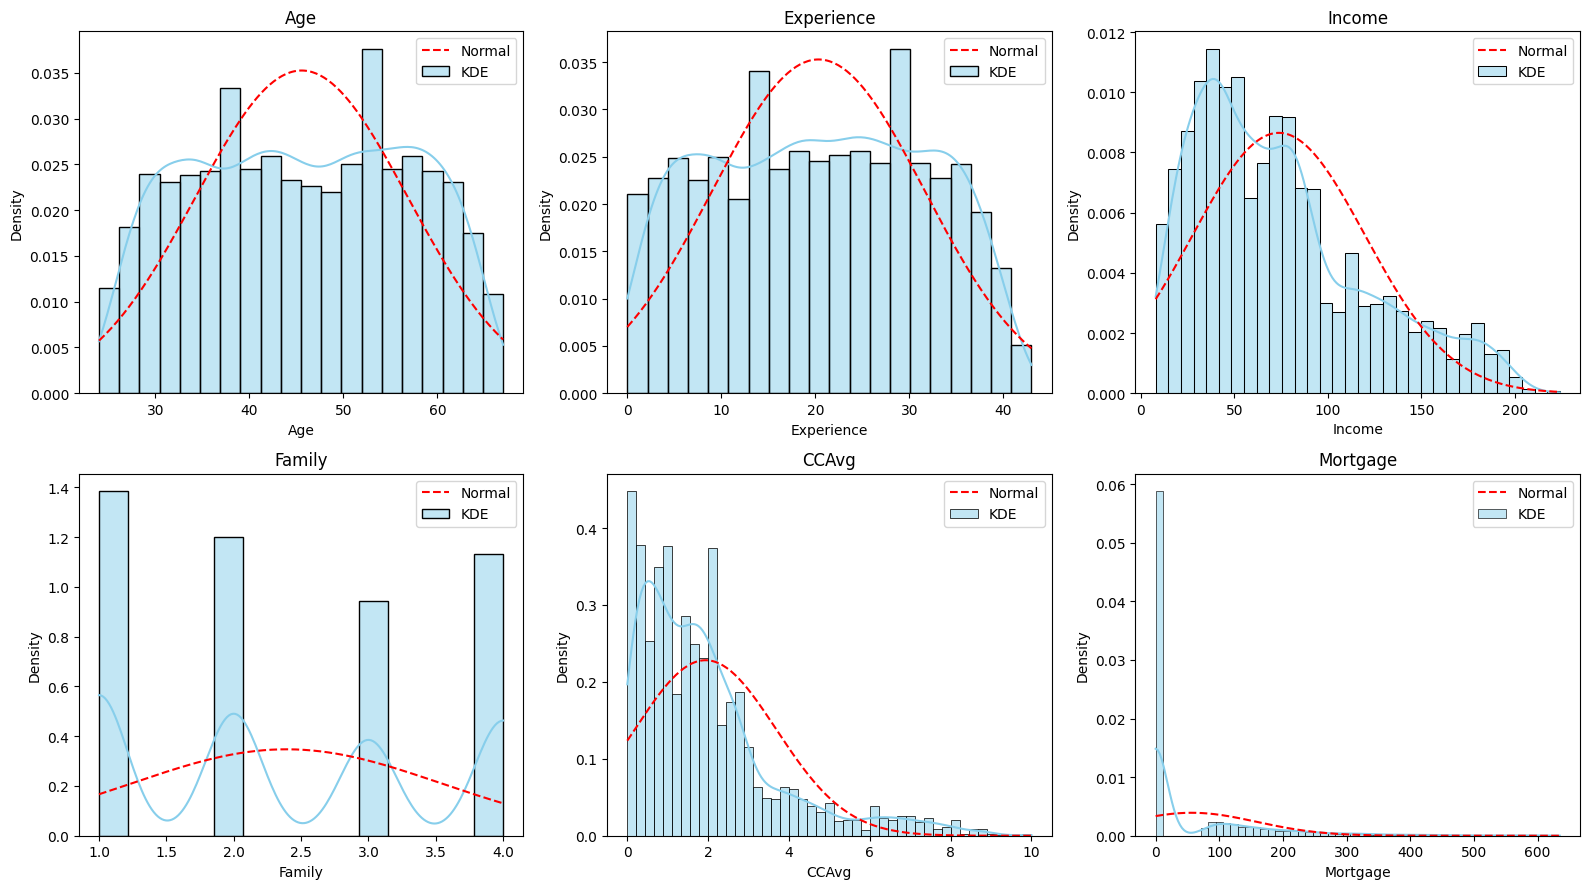

In [25]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, columna in enumerate(num_cols):
    datos = loan_df[columna]

    # Histograma con curva KDE
    sns.histplot(datos, kde=True, stat='density', ax=axes[i], color='skyblue', label='KDE')

    # Curva normal de referencia
    x = np.linspace(datos.min(), datos.max(), 200)
    axes[i].plot(x, norm.pdf(x, datos.mean(), datos.std()), color='red', linestyle='--', label='Normal')

    axes[i].set_title(columna)
    axes[i].legend()

plt.tight_layout()
plt.show()

Age: el histograma se ve bastante parejo y aplanado, las barras tienen casi la misma altura entre los 30 y 60 años y no hay un pico marcado en el centro. La curva normal es más puntiaguda que la KDE. Esto coincide con lo que calculé: una asimetría cercana a 0 (simétrica) y una curtosis negativa (platicúrtica).

Income: la mayoría de los clientes tiene ingresos entre 20 y 80 mil dólares, con el pico alrededor de 40, y después hay una cola larga hacia la derecha que llega hasta 224. Por eso la curva normal queda movida a la derecha del pico real. Esto coincide con la asimetría positiva moderada (0.84). La curtosis cercana a 0 también tiene sentido, porque aunque hay cola, no es tan extrema.

Mortgage: casi todos los datos están en 0, porque la mayoría no tiene hipoteca, y luego hay una cola muy larga y baja hasta 635. La curva normal no se parece en nada a la forma real de los datos. Esto coincide con la asimetría positiva fuerte (2.10) y con la curtosis alta (4.76), que indica un pico muy concentrado y colas largas.

Algo que no coincide tanto es que en Income la curtosis es casi 0 (como una normal), pero en el histograma la forma no se parece a una normal, porque tiene el pico corrido a la izquierda y una cola larga. Esto pasa porque la curtosis solo mide qué tan pesadas son las colas, no la forma completa, así que hay que ver el histograma además de los números.

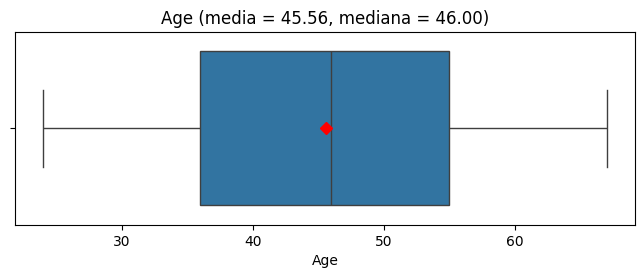

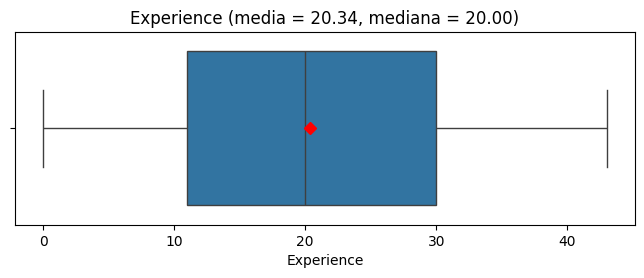

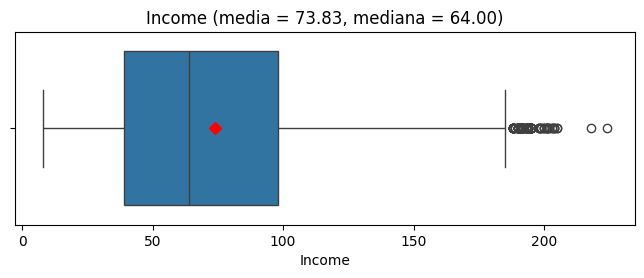

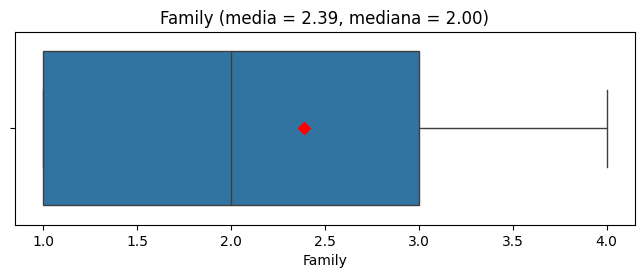

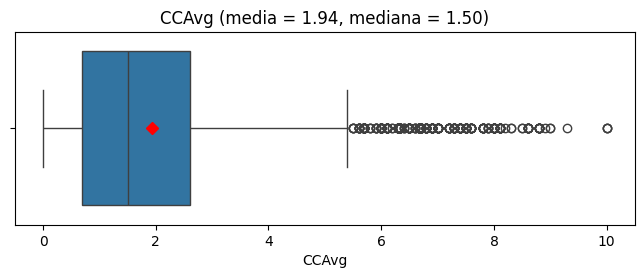

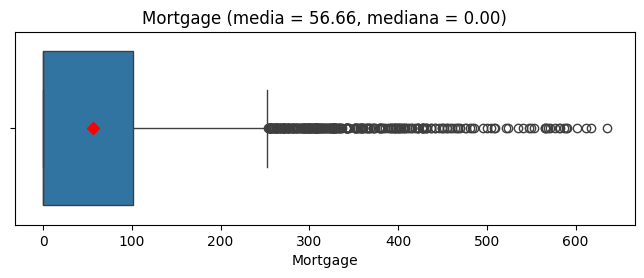

In [26]:
for columna in num_cols:
    plt.figure(figsize=(8, 2.5))
    sns.boxplot(x=loan_df[columna], showmeans=True,
                meanprops={'marker': 'D', 'markerfacecolor': 'red', 'markeredgecolor': 'red'})
    plt.title(f'{columna} (media = {loan_df[columna].mean():.2f}, mediana = {loan_df[columna].median():.2f})')
    plt.show()

La media es sensible a los valores extremos, mientras que la mediana no. Por eso, si la media es mayor que la mediana, quiere decir que hay valores altos que la están jalando hacia arriba, y la distribución tiene asimetría positiva.

En Age y Experience la media y la mediana son casi iguales (45.56 vs 46 y 20.34 vs 20), así que son distribuciones simétricas, lo cual coincide con sus valores de asimetría cercanos a 0.

En Income, CCAvg y Mortgage la media es mayor que la mediana, por lo que tienen asimetría positiva. Además, en sus boxplots se ven muchos valores atípicos del lado derecho. El caso más extremo es Mortgage, donde la mediana es 0 y la media es 56.66, porque la mayoría de los clientes no tiene hipoteca pero algunos tienen montos muy altos.

En Family la media (2.39) también es un poco mayor que la mediana (2), pero la diferencia es pequeña, así que la asimetría es leve.

8. Obtén las estadísticas descriptivas de las variables categóricas.
* Genera un gráfico de barras para cada variable. En las de alta cardinalidad, sólo incluye los 10 valores más relevantes.

In [27]:
loan_df[cat_cols].describe()

,ZIP Code,Education,Personal Loan,Securities Account,CD Account,Online,CreditCard
count,4941,4941,4941,4941,4941,4941,4941
unique,467,3,2,2,2,2,2
top,94720,1,0,0,0,1,0
freq,163,2079,4462,4426,4640,2951,3489


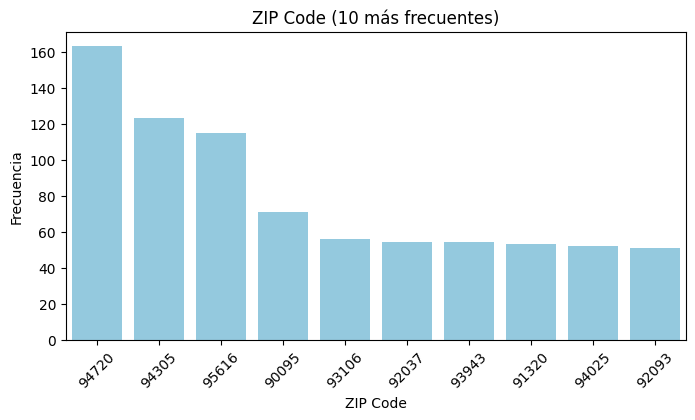

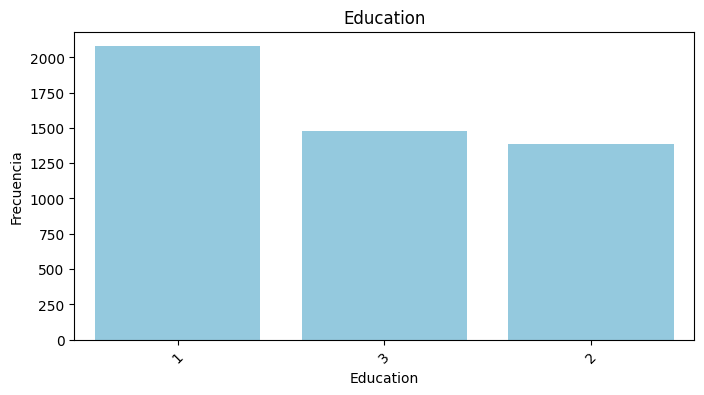

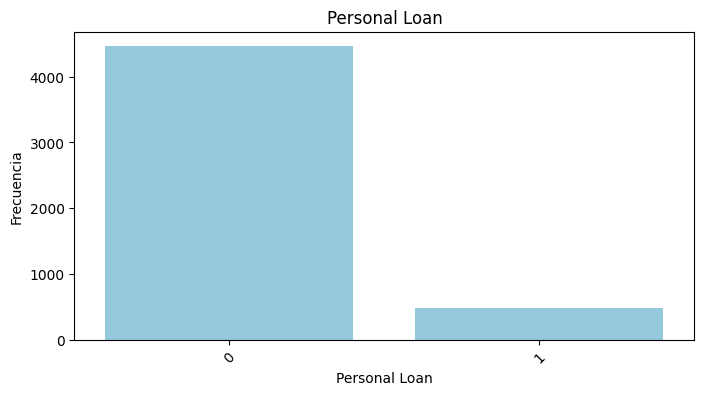

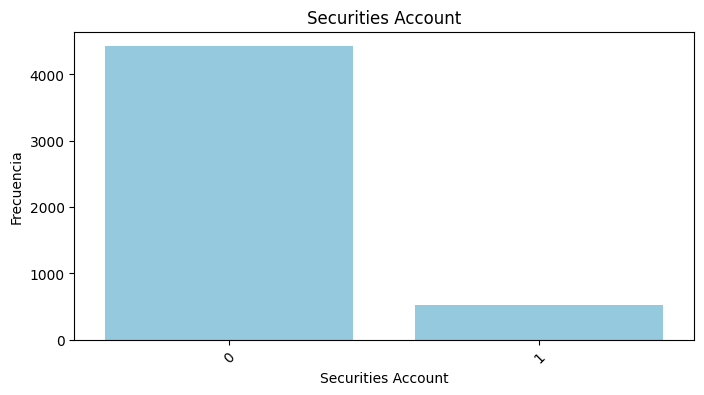

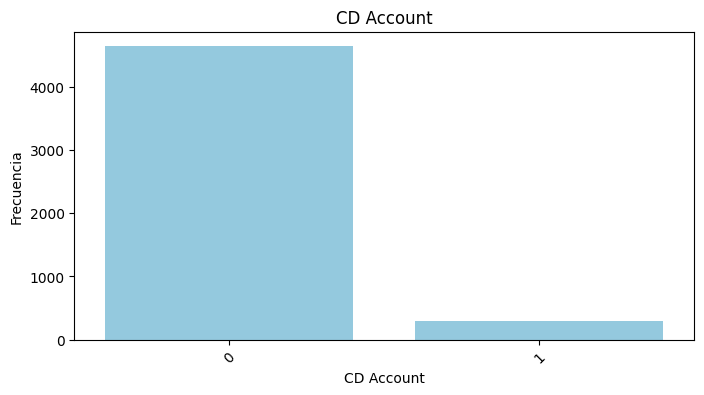

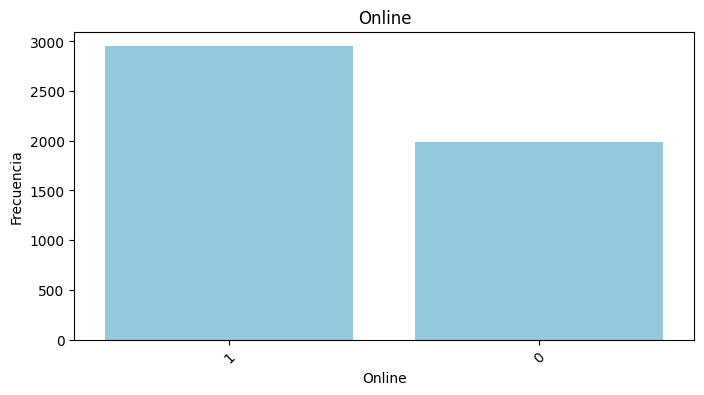

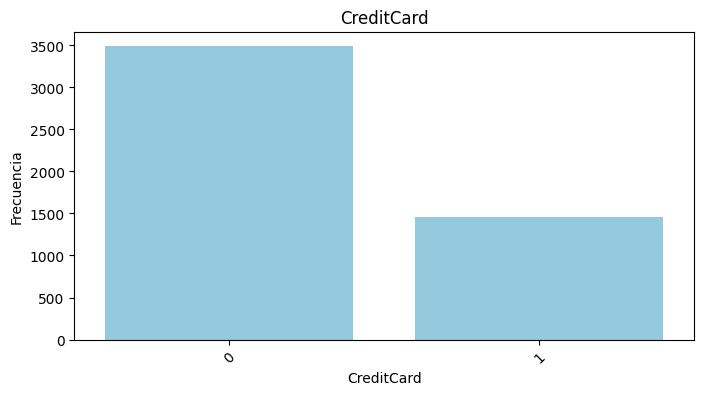

In [28]:
for columna in cat_cols:
    frecuencias = loan_df[columna].value_counts()
    titulo = columna

    # Si tiene más de 10 categorías, solo dejamos las 10 más frecuentes
    if len(frecuencias) > 10:
        frecuencias = frecuencias.head(10)
        titulo = columna + ' (10 más frecuentes)'

    plt.figure(figsize=(8, 4))
    sns.barplot(x=frecuencias.index.astype(str), y=frecuencias.values,
                order=frecuencias.index.astype(str), color='skyblue')
    plt.title(titulo)
    plt.xlabel(columna)
    plt.ylabel('Frecuencia')
    plt.xticks(rotation=45)
    plt.show()

ZIP Code tiene 467 códigos postales distintos, por eso se considera de alta cardinalidad y solo grafiqué los 10 más frecuentes. El código con más clientes es el 94720 (163), seguido del 94305 y el 95616, y del cuarto lugar en adelante la frecuencia ya es bastante pareja, entre 50 y 70 clientes.

En Education, el nivel más común es el 1 (graduado), con 2079 clientes, mientras que los niveles 2 y 3 tienen cantidades parecidas.

Lo que más me llamó la atención es que Personal Loan está muy desbalanceada: solo 479 de 4941 clientes aceptaron el préstamo, o sea, alrededor del 9.7 %. Esto es importante porque es la variable que se quiere predecir, y al tener tan pocos casos de “sí”, un modelo podría tender a predecir siempre “no”.

Securities Account y CD Account también tienen muy pocos clientes con 1 (10.4 % y 6.1 %), así que son productos poco comunes. En cambio, en Online la mayoría sí usa la banca en línea (casi el 60 %), y en CreditCard alrededor del 29 % tiene tarjeta del banco.

# Análisis exploratorio de datos (bivariado)

9. Obtén la matriz de gráficos de dispersión (*scatter matrix*) de todas las variables numéricas.
* Observa las relaciones entre las variables, selecciona un par representativo y describe los patrones o tendencias que sean evidentes.
* Para cuantificar la fuerza y dirección de las relaciones observadas, genera un mapa de calor con los valores de correlación de *Pearson*. ¿El valor numérico obtenido del par seleccionado se corresponde con lo esperado?

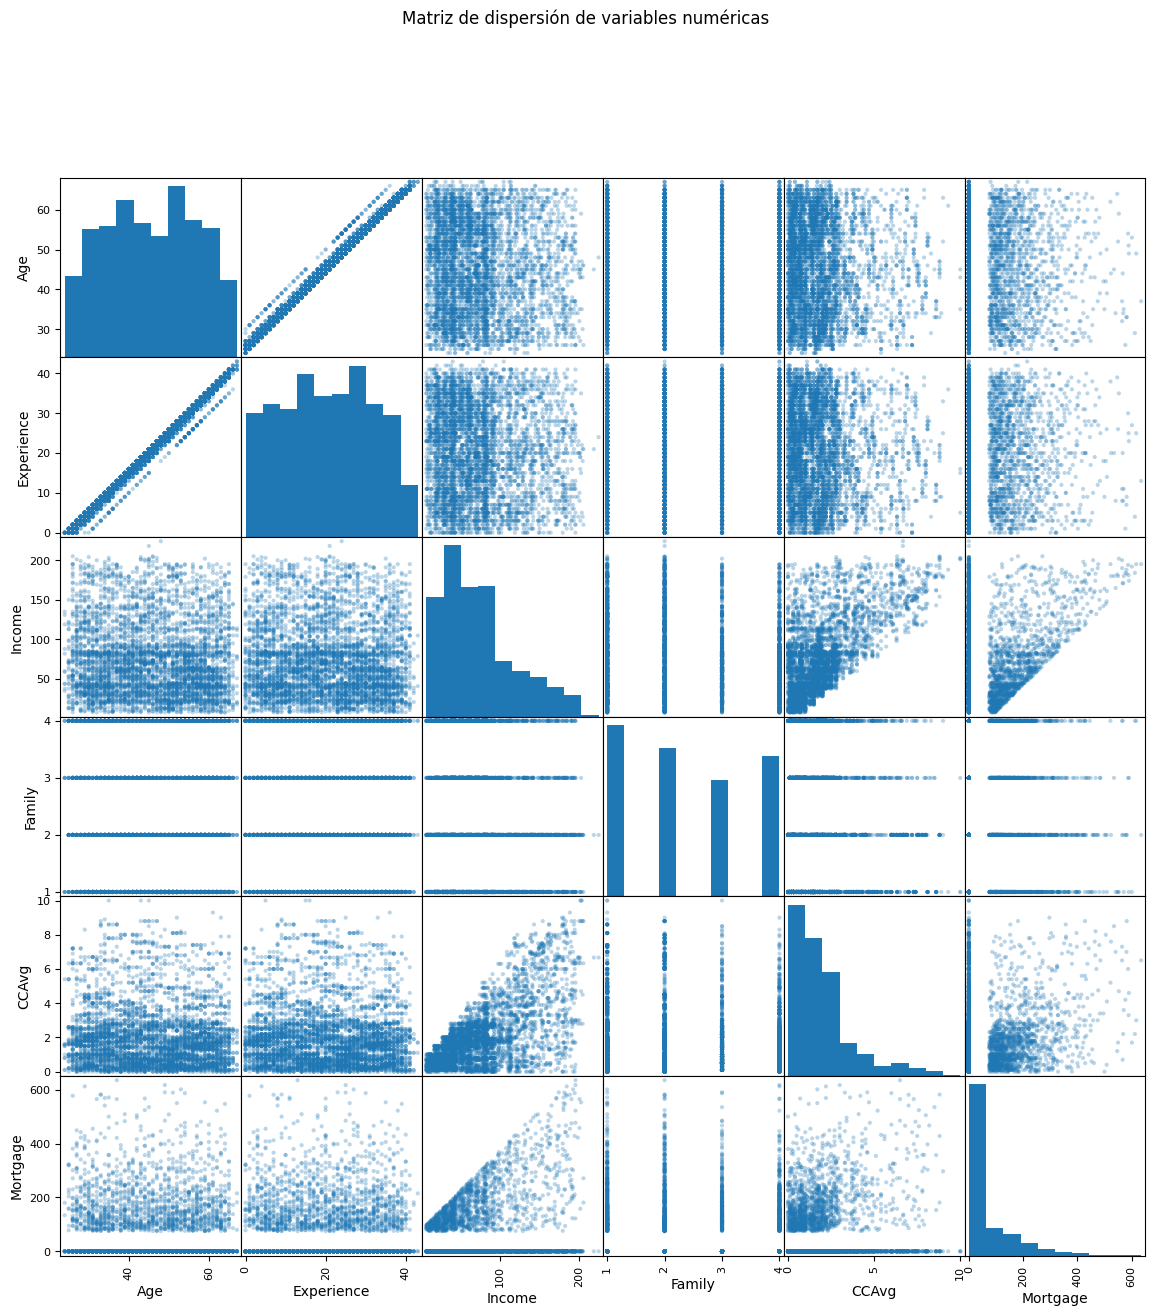

In [29]:
pd.plotting.scatter_matrix(loan_df[num_cols], figsize=(14, 14), alpha=0.3, diagonal='hist')
plt.suptitle('Matriz de dispersión de variables numéricas', y=1.0)
plt.show()

El par que escogí es Age vs. Experience, porque es la relación más evidente de toda la matriz. Los puntos forman prácticamente una línea recta que sube, lo que indica una relación lineal, positiva y muy fuerte: mientras mayor es la edad del cliente, más años de experiencia laboral tiene. Tiene mucho sentido, porque la experiencia va creciendo con los años. La línea casi no tiene dispersión, así que espero que la correlación esté muy cerca de 1.

También se ve una relación positiva entre Income y CCAvg: los clientes con más ingresos tienden a gastar más con tarjeta, aunque los puntos están más dispersos y forman como un abanico. Entre Income y Mortgage se ve una forma de triángulo, donde los que tienen ingresos más altos pueden tener hipotecas más grandes. En cambio, Age y Experience no muestran relación con Income, CCAvg ni Mortgage, porque los puntos están repartidos sin ninguna forma.

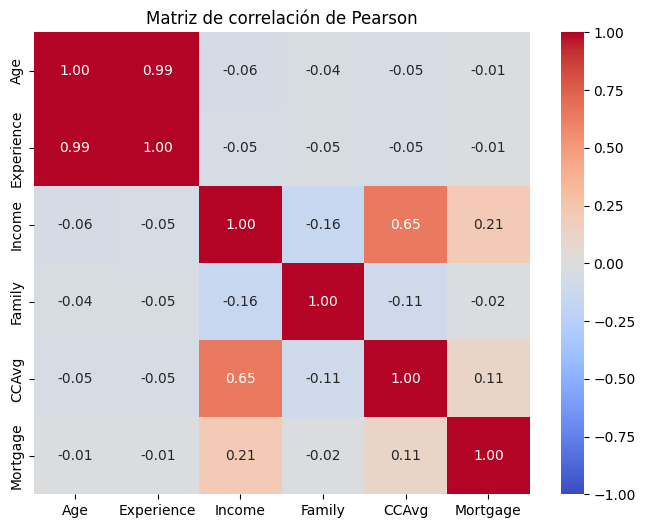

In [30]:
correlacion = loan_df[num_cols].corr(method='pearson')

plt.figure(figsize=(8, 6))
sns.heatmap(correlacion, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Matriz de correlación de Pearson')
plt.show()

Sí, el valor coincide con lo que esperaba. Entre Age y Experience la correlación es de 0.99, que es casi 1 y significa una relación positiva muy fuerte. Esto confirma lo que se veía en la scatter matrix, donde los puntos formaban prácticamente una línea recta. Tiene sentido porque la experiencia laboral aumenta casi al mismo ritmo que la edad.

Otras relaciones que se ven en el mapa de calor son Income y CCAvg (0.65), que es una correlación positiva moderada: los clientes con más ingresos tienden a gastar más con tarjeta, aunque no siempre. Entre Income y Mortgage la correlación es de 0.21, que es débil. Creo que es porque muchos clientes tienen hipoteca en 0, aunque en la scatter matrix sí se veía que los de mayor ingreso pueden tener hipotecas más altas. El resto de las variables tienen correlaciones muy cercanas a 0, así que no tienen relación lineal entre ellas.

Algo a tomar en cuenta es que, como Age y Experience están casi perfectamente correlacionadas, prácticamente dan la misma información. Si más adelante se construye un modelo, probablemente convendría usar solo una de las dos.

10. Realiza un análisis de todas las variables del dataset con respecto a la variable de salida `Personal Loan`.
* Variables numéricas: Genera box plots para comparar la distribución de cada variable según los valores de `Personal Loan`.
* Variables categóricas (sin considerar `ZIP Code`): Genera gráficos de barras apiladas que muestren la distribución relativa de `Personal Loan` dentro de cada categoría de la variable.
* Para cada grupo de variables (numéricas y categóricas), comenta al menos un hallazgo o patrón relevante observado en los gráficos generados.


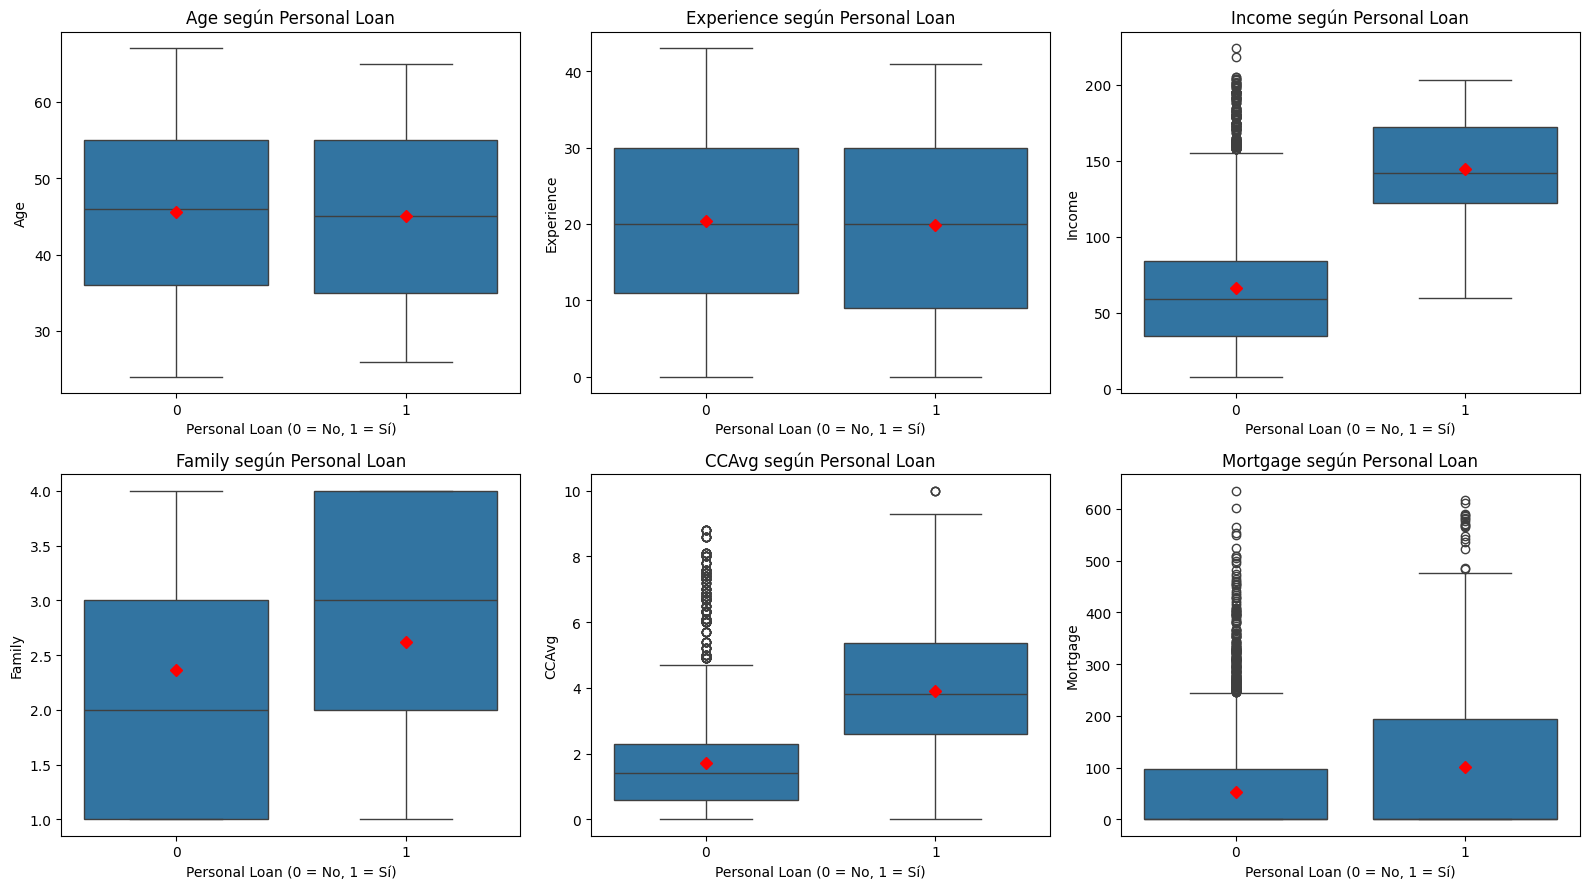

In [31]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, columna in enumerate(num_cols):
    sns.boxplot(data=loan_df, x='Personal Loan', y=columna, showmeans=True, ax=axes[i],
                meanprops={'marker': 'D', 'markerfacecolor': 'red', 'markeredgecolor': 'red'})
    axes[i].set_title(f'{columna} según Personal Loan')
    axes[i].set_xlabel('Personal Loan (0 = No, 1 = Sí)')

plt.tight_layout()
plt.show()

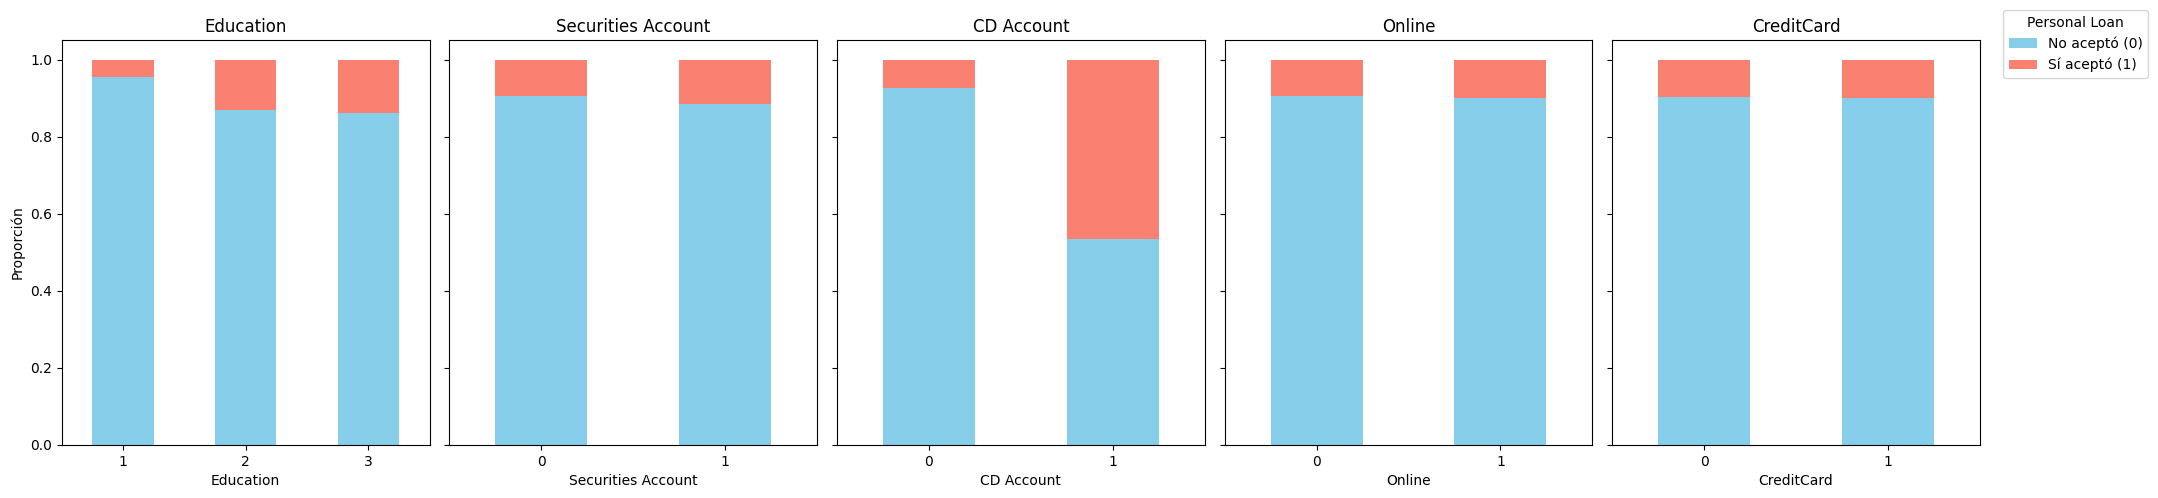

In [32]:
categoricas = [col for col in cat_cols if col not in ['ZIP Code', 'Personal Loan']]

fig, axes = plt.subplots(1, len(categoricas), figsize=(20, 5), sharey=True)

for i, columna in enumerate(categoricas):
    tabla = pd.crosstab(loan_df[columna], loan_df['Personal Loan'], normalize='index')
    tabla.plot(kind='bar', stacked=True, ax=axes[i], color=['skyblue', 'salmon'], legend=False)
    axes[i].set_title(columna)
    axes[i].set_ylabel('Proporción')
    axes[i].tick_params(axis='x', rotation=0)

fig.legend(['No aceptó (0)', 'Sí aceptó (1)'], title='Personal Loan', loc='upper right', bbox_to_anchor=(1.08, 1))
plt.tight_layout()
plt.show()

Variables numéricas: el hallazgo más claro es en Income. Los clientes que aceptaron el préstamo tienen ingresos mucho más altos, con una mediana de alrededor de 140 mil dólares, mientras que los que no aceptaron tienen una mediana de alrededor de 60 mil. Las cajas casi no se enciman, así que el ingreso parece ser una variable muy importante para predecir si un cliente acepta el préstamo. Algo parecido pasa con CCAvg: los que aceptaron gastan más del doble con tarjeta. También se ve que los que aceptaron tienen hipotecas un poco más altas y familias un poco más grandes. En cambio, en Age y Experience las cajas son casi iguales, así que la edad y la experiencia no parecen influir.

Variables categóricas: el patrón más fuerte está en CD Account. Casi la mitad de los clientes que tienen un certificado de depósito aceptaron el préstamo, mientras que de los que no tienen, solo alrededor del 7 % lo aceptó. Esto puede ser porque los clientes con CD ya tienen más relación con el banco y confían más en él. En Education también se ve una diferencia: los clientes con nivel 1 casi no aceptan el préstamo, mientras que los de nivel 2 y 3 lo aceptan más. En Securities Account, Online y CreditCard la proporción de los que aceptaron es casi la misma en ambas categorías, así que no parecen tener mucha relación con Personal Loan.

---

**Declaración de uso de IA**

Anthropic. (2026). Claude (basado en Claude Opus 5.5) [Modelo de lenguaje grande], utilizado para generación de código, depuración y redacción de propuestas de respuesta. https://claude.ai/

---